# 실습 10. 스펙트럼 분석과 필터링

## 오늘의 목표

1. Niño3.4 지수를 **시간 도메인**이 아니라 **주기 도메인**에서 본다 (파워 스펙트럼).
2. 시계열에서 원하는 주기만 남기는 **필터링**의 원리를 설명한다.

## Recap (Class 10)

- **푸리에 변환**: 데이터를 서로 다른 주기함수(삼각함수)의 **선형합**으로 나타내는 방법 (시간 도메인 ↔ 주기 도메인)
- **파워**: 그 데이터에 그 주기함수가 **얼마나 들어 있는가**
- **필터링**: 보고자 하는 주기함수만 **골라서** 보는 것

> **★ 핵심 코드** 표시가 있는 셀은 과제에 응용할 핵심 코드이다.

In [1]:
# ★ 핵심 코드
import numpy             as np
import matplotlib.pyplot as plt
import xarray as xr
import math
from statsmodels.tsa.stattools  import acf
from waveletFunctions    import *      # waveletFunctions.py 안의 모든 함수를 불러온다 (notebooks 폴더에 있어야 한다)

## 1. Make time series (Niño3.4 index)

In [2]:
# ★ 핵심 코드
################ Make time series ################
dset = xr.open_dataset('../data/sst.mnmean.nc')
sst = dset['sst']

#------------ Calculate Nino index ---------
nino34 = sst.where((sst.lat<5) & (sst.lat>-5) & (sst.lon>190) & (sst.lon<240), drop=True).mean(dim=['lat','lon'])

#---------- Calculate climatology ----------
clim = nino34.sel(time=slice('1982-01','2018-12')).groupby('time.month').mean(dim='time')

#---------- Calculate anomalies ------------
sst = (nino34.groupby('time.month') - clim)     # anomaly = 같은 달의 1982–2018 월별 평균(기후값)을 뺀 값 → 매년 반복되는 평균 계절 변화 제거

#----- Calculate autocorrelation and confidence intervals ---
acf_total, conf = acf(sst, alpha=0.05, nlags=len(sst), fft=True)   # red noise 기준선(유의성 검정)에 쓴다

### (참고) 함수로 묶기

위 셀의 과정(영역 평균 → 기후값 → anomaly)을 **함수 하나**로 묶어 두면, 영역이나 기간만 바꿔 다른 지수도 바로 만들 수 있다.
이런 함수들을 `.py` 파일에 모아 두고 `import` 해서 쓰는 것이 **모듈**이다 (`waveletFunctions.py` 도 같은 방식).

In [3]:
# (참고) Niño 지수 계산을 함수 하나로 묶기
def calc_nino_index(path, lat=(-5, 5), lon=(190, 240), base=('1982-01', '2018-12')):
    """월평균 SST 파일에서 영역 평균 SST anomaly (Niño 지수) 시계열을 만든다.

    path : SST netCDF 파일 경로
    lat  : (남, 북) 위도 범위      — 기본값 Niño3.4 = 5°S–5°N
    lon  : (서, 동) 경도 범위 (°E) — 기본값 Niño3.4 = 170°W–120°W = 190°E–240°E
    base : 기후값(월별 평균)을 계산할 기준 기간
    """
    sst = xr.open_dataset(path)['sst']

    #------------ 영역 평균 ---------
    box   = (sst.lat > lat[0]) & (sst.lat < lat[1]) & (sst.lon > lon[0]) & (sst.lon < lon[1])
    index = sst.where(box, drop=True).mean(dim=['lat', 'lon'])

    #---------- 기후값: 기준 기간의 월별 평균 ----------
    clim = index.sel(time=slice(*base)).groupby('time.month').mean(dim='time')

    #---------- anomaly: 같은 달의 기후값을 뺀다 ------------
    return index.groupby('time.month') - clim


nino34_anom = calc_nino_index('../data/sst.mnmean.nc')                       # Niño3.4
nino3_anom  = calc_nino_index('../data/sst.mnmean.nc', lon=(210, 270))       # Niño3  (150°W–90°W)
nino4_anom  = calc_nino_index('../data/sst.mnmean.nc', lon=(160, 210))       # Niño4  (160°E–150°W)

print('위 셀의 sst 와 같은가?', np.allclose(nino34_anom, sst))

위 셀의 sst 와 같은가? True


## 2. Wavelet power spectrum

푸리에 변환과 비슷하지만, 짧은 파동 조각(창)을 **시간을 따라 옮겨 가며** 비교하는 **wavelet 변환**을 쓴다.
파라미터는 다 몰라도 된다. 바꿔 볼 만한 것은 `siglev`(유의수준)와 `dj`(주기를 얼마나 잘게 나눠 볼지)뿐이다.

### (참고) 왜 wavelet 인가?

주기가 **시간에 따라 바뀌는** 두 합성 시계열을 만들어 비교해 보자.
- A: 앞 절반은 **짧은 주기(16개월)**, 뒤 절반은 **긴 주기(64개월)**
- B: 순서를 바꿔 앞 절반은 **긴 주기**, 뒤 절반은 **짧은 주기**

푸리에 파워 스펙트럼은 "어떤 주기가 **얼마나**" 들어 있는지만 알려 주므로 A와 B가 거의 똑같다.
wavelet 은 짧은 파동 조각(창)을 시간을 따라 옮겨 가며 보므로 "**언제**" 그 주기가 있었는지까지 보인다.
실제 기후 자료(예: ENSO)는 시기마다 변동의 세기가 달라서 wavelet 이 응용도가 더 좋다.

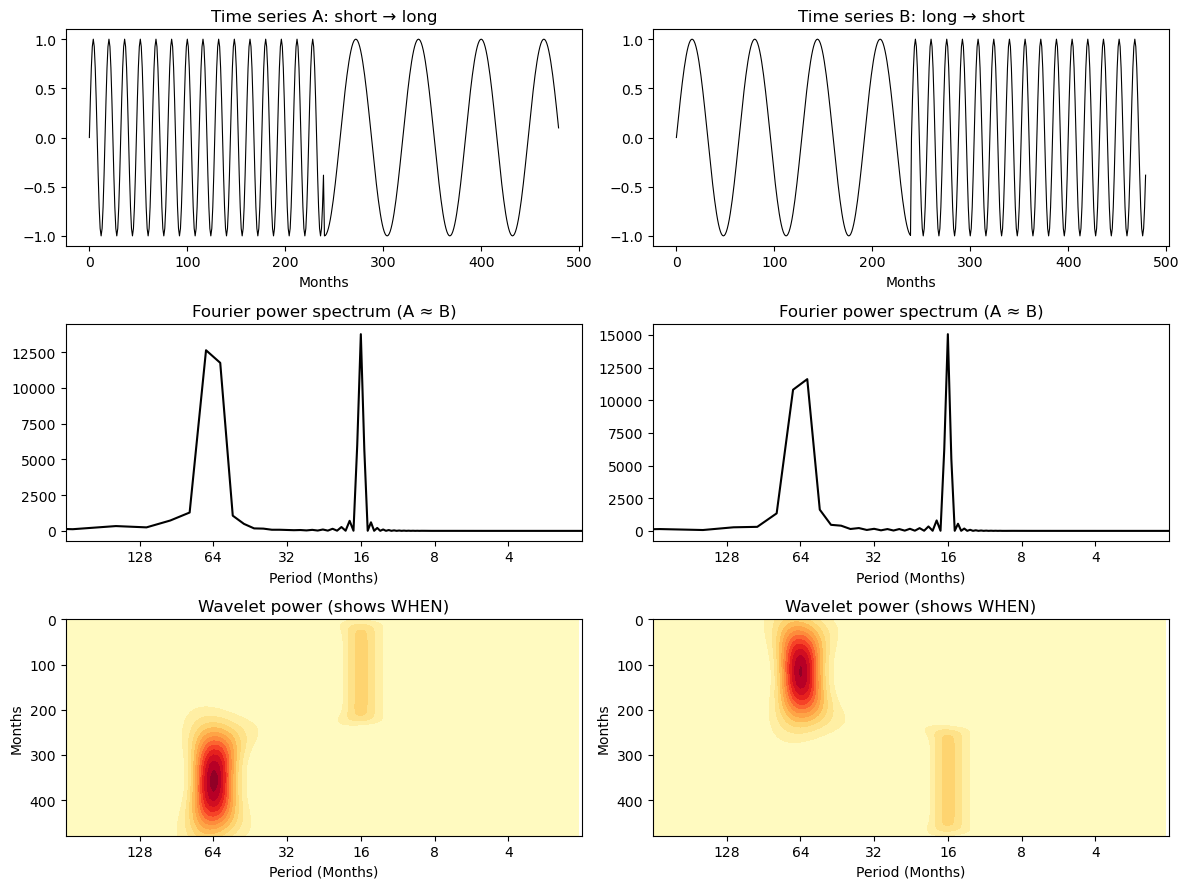

In [4]:
# (참고) 주기가 시간에 따라 바뀌는 합성 시계열 — 푸리에 vs wavelet
nt = 480                                   # 40년치 월자료
t  = np.arange(nt)
half = t < nt//2
short_p, long_p = 16, 64                   # 주기 (개월)
sigA = np.where(half, np.sin(2*np.pi*t/short_p), np.sin(2*np.pi*t/long_p))
sigB = np.where(half, np.sin(2*np.pi*t/long_p),  np.sin(2*np.pi*t/short_p))

fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for j, (sig, name) in enumerate([(sigA, 'A: short → long'), (sigB, 'B: long → short')]):
    # 1) 시계열
    axes[0, j].plot(t, sig, 'k', lw=0.8)
    axes[0, j].set_title(f'Time series {name}')
    axes[0, j].set_xlabel('Months')

    # 2) 푸리에 파워 스펙트럼 (주기 축)
    ck   = np.fft.rfft(sig - sig.mean())
    freq = np.fft.rfftfreq(nt, d=1)
    axes[1, j].plot(1/freq[1:], np.abs(ck[1:])**2, 'k')
    axes[1, j].set_xscale('log', base=2)
    axes[1, j].set_xticks([4, 8, 16, 32, 64, 128], [4, 8, 16, 32, 64, 128])
    axes[1, j].set_xlim(256, 2)                          # 왼쪽 = 장주기, 오른쪽 = 단주기 (뒤쪽 그림과 동일)
    axes[1, j].set_title('Fourier power spectrum (A ≈ B)')
    axes[1, j].set_xlabel('Period (Months)')

    # 3) wavelet power (x = 주기, y = 시간)
    w, per, sc, co = wavelet(sig, 1, 1., 0.05, 2, np.round(np.log2(nt/2)/0.05), 'MORLET')
    axes[2, j].contourf(np.log2(per), t, (np.abs(w)**2).T, levels=12, cmap='YlOrRd')
    axes[2, j].set_xticks(np.arange(2, 8), 2**np.arange(2, 8))
    axes[2, j].set_xlim(np.log2(256), np.log2(2))        # 왼쪽 = 장주기, 오른쪽 = 단주기
    axes[2, j].invert_yaxis()                            # 위 = 처음, 아래 = 나중
    axes[2, j].set_title('Wavelet power (shows WHEN)')
    axes[2, j].set_xlabel('Period (Months)'); axes[2, j].set_ylabel('Months')
plt.tight_layout()
plt.show()

In [5]:
# ★ 핵심 코드
################### Computation ###################
#---------- Set wavelet parameters ----------
n    = len(sst)
dt   = 1                            # unit: month
time = sst.time.values              # construct time array
siglev = 0.95                       # significance level (e.g., 95%, 99%)
pad  = 1.                           # pad the time series with zeroes (recommended)
dj   = 0.01                         # lower => better resolution
s0   = 2 * dt                       # this says start at a scale of 2 months
j1   = np.round((np.log2(n*dt/s0))/dj)
lag1 = acf_total[1]
mother = 'MORLET'                   # options: 'MORLET', 'PAUL', 'DOG'

#--- Wavelet Transform & significance levels ----
wave, period, scale, coi = wavelet(sst, dt, pad, dj, s0, j1, mother)
realpart = np.real(wave)
power = (np.abs(wave))**2           # wavelet power (주기 × 시간) ≈ c_k^2

#---- Global wavelet spectrum & significance levels ----
# wavelet() 은 입력에서 평균만 빼고 표준편차로 나누지 않으므로 power 의 단위는 이미 (°C)^2 이다
variance  = (sst.std().values)**2                 # wave_signif 의 red noise 기준선 크기를 맞추는 데 쓴다
global_ws = power.mean(axis=1)                    # power 를 시간에 대해 평균 → 주기별 평균 파워
dof = n - scale                                   # the -scale corrects for padding at edges
global_signif, global_fft_theor = wave_signif(variance, dt, scale, 1, lag1, siglev, dof, mother)

### (참고) wavelet map 을 시간 평균하면 power spectrum

- 위 그림: **x = 주기**, **y = 시간** (위 → 아래로 시간이 흐른다), 색 = 그 시각·그 주기의 파워
- 아래 그림: **x = 주기** (위와 같은 축), **y = 파워** — 뒤쪽 4번 그림과 같은 방향
- 위 그림의 **세로 한 줄**(한 주기)을 시간에 대해 평균하면 → 아래 그림에서 **같은 x 위치의 점 하나**가 된다
  (`global_ws = power.mean(axis=1)`, `power` 의 모양은 (주기 × 시간))

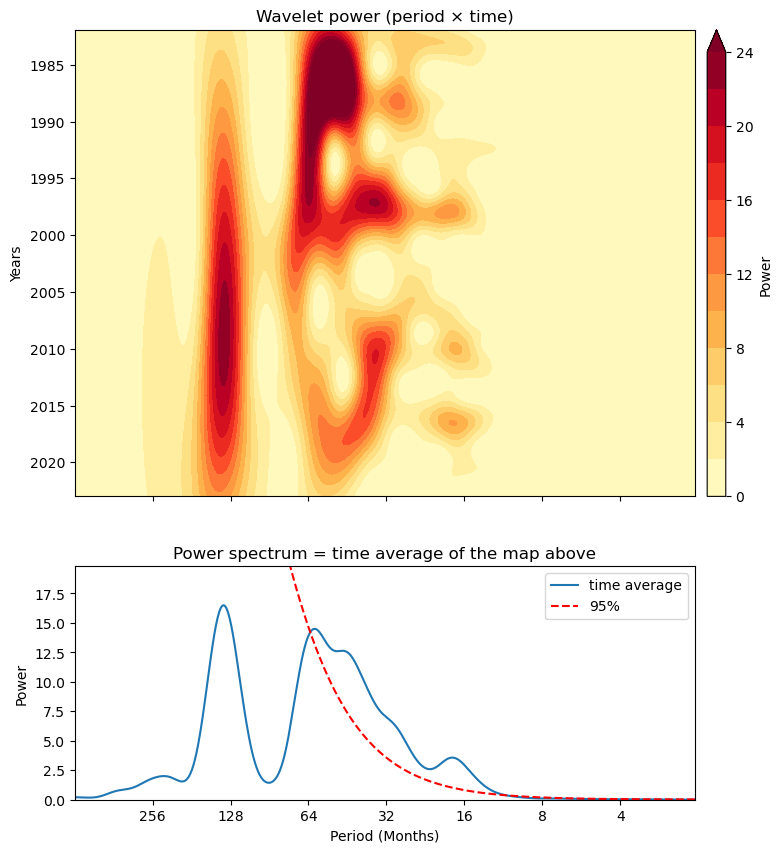

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1.5]})

#------------- 위: wavelet power map (x = 주기, y = 시간) -------------
cs = ax1.contourf(np.log2(period), time, power.T, levels=np.linspace(0, 24, 13), cmap='YlOrRd', extend='max')
ax1.invert_yaxis()                                    # 위 = 과거, 아래 = 최근
ax1.set_title('Wavelet power (period × time)')
ax1.set_ylabel('Years')
cax = ax1.inset_axes([1.02, 0, 0.03, 1])               # 색 막대를 지도 오른쪽 바깥에 둔다
fig.colorbar(cs, cax=cax, label='Power')

#------------- 아래: 시간 평균 → power spectrum (x = 주기, y = 파워) -------------
ax2.plot(np.log2(period), global_ws, label='time average')
ax2.plot(np.log2(period), global_signif, 'r--', label='95%')
ax2.set_title('Power spectrum = time average of the map above')
ax2.set_xlabel('Period (Months)')
ax2.set_ylabel('Power')
ax2.set_ylim(0, max(global_ws)*1.2)
ax2.legend(loc='upper right')

tickval = np.arange(int(np.log2(min(period))), int(np.log2(max(period)))+1, 1)
ax2.set_xticks(tickval, np.power(2, tickval))
ax2.set_xlim(np.log2(max(period)), np.log2(min(period)))   # 왼쪽 = 장주기, 오른쪽 = 단주기 (뒤쪽 그림과 동일)
plt.show()

## 3. Filtering

시간 도메인 → 주기 도메인 → **남길 주기의 wavelet 계수만 고름** (`avg` = 마스크) → 다시 시간 도메인 (`xn`)

즉 **약 2–8년(24–96개월)에 해당하는 wavelet 계수만 골라 시계열을 다시 만든다.**
기준은 `scale` 이 아니라 `period` 로 잡는다 (Morlet 에서는 period ≈ 1.03 × scale).

In [7]:
# ★ 핵심 코드
#---------------- Filtering ----------------
avg = (period >= 24) & (period < 96)                 # 2–8년 주기의 계수만 고르는 마스크 (band-pass)
# avg = (period < 24)                                 # High-pass: 2년보다 짧은 주기만
# avg = (period >= 96)                                # Low-pass: 8년보다 긴 주기만
cdelta    = 0.776                                     # cdelta=0.776 for morlet wavelet
scale_avg = scale[:, np.newaxis].dot(np.ones(n)[np.newaxis, :])
psi       = math.pi**(-1/4)
xnc       = (dj*math.sqrt(dt))/(cdelta*psi)
xnv       = realpart/np.sqrt(scale_avg)
xn        = xnc*sum(xnv[avg,:])                       # Filtered time series

## 4. Plotting

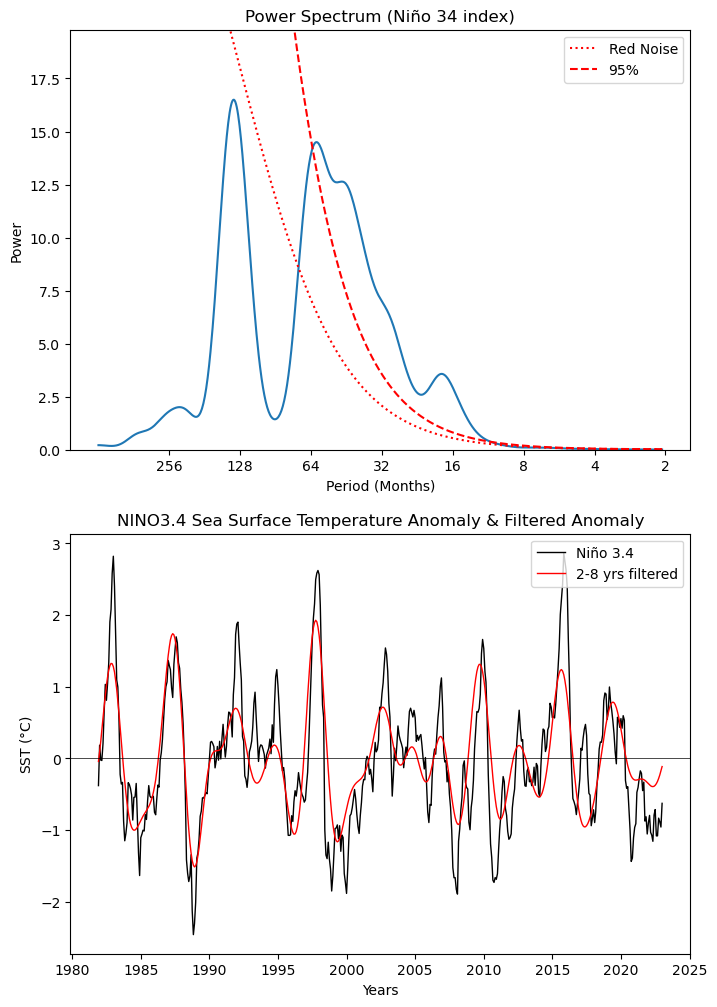

In [8]:
# ★ 핵심 코드
##########################  Plotting  ############################
plt.figure(figsize=(8,12))

#------------- Sub-Figure 1 - Power spectrum -------------
ax1 = plt.subplot(211)
ax1.plot(np.log2(period), global_ws)
ax1.plot(np.log2(period), global_fft_theor, 'r:', label="Red Noise")
ax1.plot(np.log2(period), global_signif, 'r--', label="95%")
ax1.set_xlabel('Period (Months)')
ax1.set_ylabel('Power')
ax1.set_title('Power Spectrum (Niño 34 index)')
ax1.invert_xaxis()                                    # 왼쪽 = 장주기, 오른쪽 = 단주기
ax1.legend(loc='upper right')
tickval = np.arange(int(np.log2(min(period))), int(np.log2(max(period)))+1, 1)
plt.xticks(tickval, np.power(2, tickval))
plt.ylim(0, max(global_ws)*1.2)

#------ Sub-Figure 2 - Original & Filtered timeseries -----
ax2 = plt.subplot(212)
ax2.plot(time, sst, 'black', lw=1, label="Niño 3.4")
ax2.plot(time, xn, 'red', lw=1, label="2-8 yrs filtered")
ax2.axhline(0, color='black', linewidth=0.5)
ax2.set_xlabel('Years')
ax2.set_ylabel('SST ($\\degree$C)')
ax2.set_title('NINO3.4 Sea Surface Temperature Anomaly & Filtered Anomaly')
ax2.legend(loc='upper right')
plt.show()

**그림 읽는 법**
- 빨간 점선 = red noise (귀무가설), 빨간 파선 = 95% 유의선. 이 선 위로 올라가야 유의하다.
- **3–5년 부근이 red noise 기준에서 95% 유의하며, ENSO 의 시간 규모와 겹친다.** 약 11년 피크는 가장 높지만 유의선 아래라 유의하지 않다.
- 아래: 검정 = 원래 자료, 빨강 = 2~8년 band-pass 결과. `avg` 를 바꿔 low/high-pass 도 해 보자.

## Homework

Perform EOF analysis for monthly North Pacific (120°E–260°E; 20°N–70°N) SST (Sea Surface Temperature) and then perform spectral analysis using PC time series 1 (= PDO-Pacific Decadal Oscillation index).